**Decision Trees**

A Decision Tree is a supervised machine learning algorithm that can be used for both classification and regression tasks. It follows a hierarchical tree structure consisting of a root node, branches, internal nodes, and leaf nodes. It works similar to a flowchart, where decisions are made step by step, as follows:

1. Internal nodes represent tests performed on attributes
2. Branches represent the possible values of attributes
3. Leaf nodes represent the final decisions or predictions.

-> Parent node: When two connected nodes are considered, the node that is placed higher in the hierarchy is called the parent node.

-> Child node: When two connected nodes are considered, the node that is placed lower in the hierarchy is called the child node.

-> Root node: The first node from which the decision tree begins is called the root node. It does not have a parent node and acts as the starting point of the tree. (dark blue node in the above image)

-> Leaf Node/leaf: The nodes located at the end of the tree and having no child nodes are called leaf nodes, or simply leaves. (green nodes in the above image)

-> Internal nodes/nodes: The nodes that occur between the root node and the leaf nodes are known as internal nodes, or simply nodes. Internal nodes have a parent and at least one child. (red nodes in the above image)

-> Splitting: The process of dividing a node into two or more sub-nodes, or creating two or more child nodes from a node.

-> Decision node: When a parent node is divided into two or more child nodes, that parent node is called a decision node.

 Pruning: Removing a sub-node from a decision node is known as pruning. It can be considered the opposite process of splitting.

 Branch/Sub-tree: A smaller section or portion of the complete decision tree is called a branch or sub-tree.

In [1]:
import numpy as np
import pandas as pd

In [3]:
# Load and prepare Titanic data
import os
if not os.path.exists('/content/train.csv'):
    from google.colab import files
    print('Please upload train.csv')
    files.upload()

titanic_train = pd.read_csv('/content/train.csv')   # Read the data

# Input median Age for NA Age values
new_age_var = np.where(titanic_train['Age'].isnull(),
                       28,
                       titanic_train['Age'])

titanic_train['Age'] = new_age_var

Please upload train.csv


Saving train.csv to train.csv


In [4]:
from sklearn import tree
from sklearn import preprocessing

In [5]:
# Initialize label encoder
label_encoder = preprocessing.LabelEncoder()

# Convert Sex variable to numeric
encoded_sex = label_encoder.fit_transform(titanic_train["Sex"])

# Initialize model
tree_model = tree.DecisionTreeClassifier()

# Train the model
tree_model.fit(X = pd.DataFrame(encoded_sex),
               y = titanic_train["Survived"])

DecisionTreeClassifier()

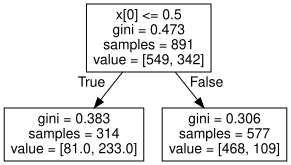

In [6]:
try:
    import graphviz
except ImportError:
    !pip -q install graphviz
    import graphviz

# Save tree as dot file
dot_data = tree.export_graphviz(tree_model, out_file=None)
graph = graphviz.Source(dot_data) # AP24110010563
graph

The graph of the tree shows that it contains only one decision node, which divides the data according to the Sex variable (the first variable, X[0]). All 314 female passengers are placed in one leaf node, while all 577 male passengers are placed in another leaf node.

Let's use this tree to make predictions and display the results in a table:

In [7]:
# Get survival probability
preds = tree_model.predict_proba(X = pd.DataFrame(encoded_sex))

pd.crosstab(preds[:,0], titanic_train["Sex"])

Sex,female,male
row_0,,
0.257962,314,0
0.811092,0,577


The table indicates that the decision tree has created a simple gender-based model in which all females are predicted to survive, while all males are predicted not to survive.

Let's create a new decision tree by adding the passenger class variable and observe how it changes the resulting predictions:

In [8]:
# Make data frame of predictors
predictors = pd.DataFrame([encoded_sex, titanic_train["Pclass"]]).T

# Train the model
tree_model.fit(X = predictors,
               y = titanic_train["Survived"])

DecisionTreeClassifier()

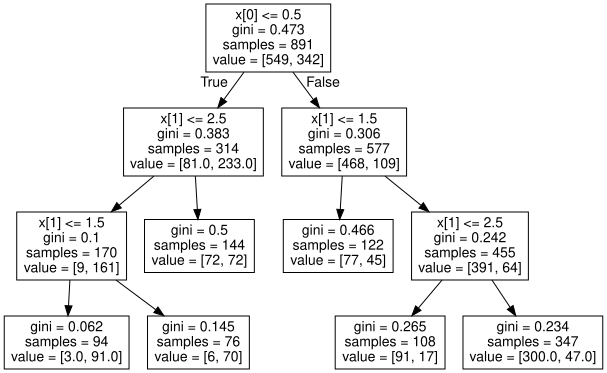

In [9]:
# Save tree as dot file
dot_data = tree.export_graphviz(tree_model, out_file=None)
graph = graphviz.Source(dot_data)
graph

In [10]:
# Get survival probability
preds = tree_model.predict_proba(X = predictors)

# Create a table of predictions by sex and class
pd.crosstab(preds[:,0], columns = [titanic_train["Pclass"],
                                   titanic_train["Sex"]])

Pclass        1           2           3     
Sex      female male female male female male
row_0                                       
0.031915     94    0      0    0      0    0
0.078947      0    0     76    0      0    0
0.500000      0    0      0    0    144    0
0.631148      0  122      0    0      0    0
0.842593      0    0      0  108      0    0
0.864553      0    0      0    0      0  347

It can be observed that the more complex model still predicts a higher survival rate for women than men, but passenger class also influences the predictions. Women belonging to third class have a predicted death probability of about 50%, whereas women from first class are predicted to have a death probability of less than 5%.

As more variables are added to a decision tree, it can perform more yes/no decisions, which results in a deeper and more complicated tree. However, adding excessive complexity can cause the decision tree to overfit the training data, which may result in poor generalization when the model is applied to unseen data. Let's investigate this by creating a larger tree using a few more variables:

In [11]:
predictors = pd.DataFrame([encoded_sex,
                           titanic_train["Pclass"],
                           titanic_train["Age"],
                           titanic_train["Fare"]]).T

# Initialize model with maximum tree depth set to 8
tree_model = tree.DecisionTreeClassifier(max_depth = 8)

tree_model.fit(X = predictors,
               y = titanic_train["Survived"])

DecisionTreeClassifier(max_depth=8)

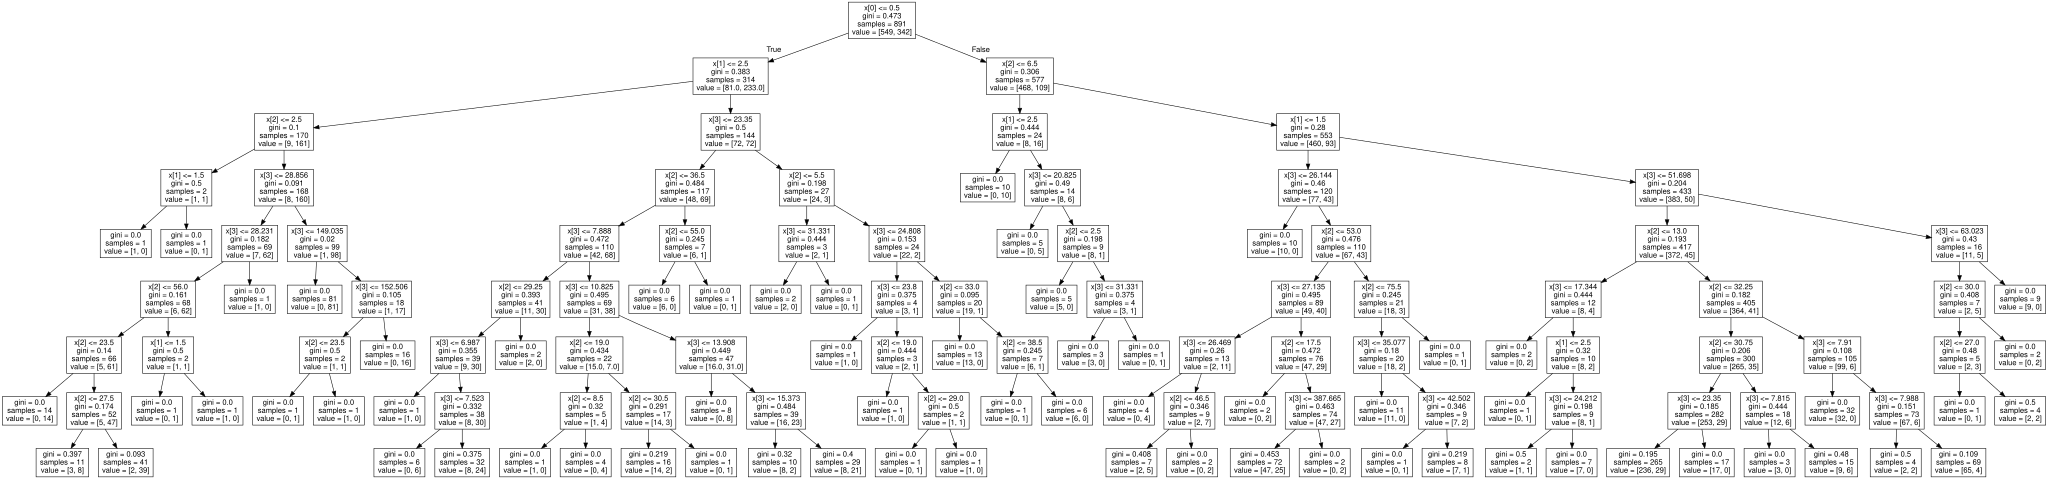

In [12]:
# Save tree as dot file
dot_data = tree.export_graphviz(tree_model, out_file=None)
graph = graphviz.Source(dot_data)
graph

The image above demonstrates how complicated a decision tree can become when additional explanatory variables are included. The complexity of the tree can be controlled by changing some of the default parameters of the decision tree function. For example, the tree created above uses max_depth = 8, which restricts the tree to a maximum depth of 8. Without this restriction, the resulting tree would have been much larger.

For interest, let's check the accuracy of this decision tree model on the training data:

In [13]:
# Read and prepare test data
import os
if not os.path.exists('/content/test.csv'):
    from google.colab import files
    print('Please upload test.csv')
    files.upload()

titanic_test = pd.read_csv('/content/test.csv')

# Impute missing Age values
new_age_var = np.where(
    titanic_test['Age'].isnull(),
    28,
    titanic_test['Age']
)

# Impute missing Fare values
new_fare_var = np.where(
    titanic_test['Fare'].isnull(),
    50,
    titanic_test['Fare']
)

titanic_test['Age'] = new_age_var
titanic_test['Fare'] = new_fare_var

print(titanic_test.head())

Please upload test.csv


Saving test.csv to test.csv
   PassengerId  Pclass                                          Name     Sex  \
0          892       3                              Kelly, Mr. James    male   
1          893       3              Wilkes, Mrs. James (Ellen Needs)  female   
2          894       2                     Myles, Mr. Thomas Francis    male   
3          895       3                              Wirz, Mr. Albert    male   
4          896       3  Hirvonen, Mrs. Alexander (Helga E Lindqvist)  female   

    Age  SibSp  Parch   Ticket     Fare Cabin Embarked  
0  34.5      0      0   330911   7.8292   NaN        Q  
1  47.0      1      0   363272   7.0000   NaN        S  
2  62.0      0      0   240276   9.6875   NaN        Q  
3  27.0      0      0   315154   8.6625   NaN        S  
4  22.0      1      1  3101298  12.2875   NaN        S  


In [14]:
# Convert test variables to match model features
encoded_sex_test = label_encoder.fit_transform(titanic_test["Sex"])

test_features = pd.DataFrame([encoded_sex_test,
                              titanic_test["Pclass"],
                              titanic_test["Age"],
                              titanic_test["Fare"]]).T

In [15]:
# Make test set predictions
test_features = pd.DataFrame(
    test_features,
    columns=["Sex", "Pclass", "Age", "Fare"]
)

test_preds = tree_model.predict(X=test_features)

# Create a submission for Kaggle
submission = pd.DataFrame({
    "PassengerId": titanic_test["PassengerId"],
    "Survived": test_preds
})

# Save submission to CSV
submission.to_csv(
    "tutorial_dectree_submission.csv",
    index=False
)

print(submission.head())

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Select features and target
X = titanic_train[["Sex", "Pclass", "Age", "Fare"]].copy()
y = titanic_train["Survived"]

# Convert categorical Sex values into numeric columns
X = pd.get_dummies(X, columns=["Sex"], dtype=int)

# Handle missing values
X = X.fillna(X.median())

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=12,
    stratify=y
)

# Train the Decision Tree
model = DecisionTreeClassifier(
    max_depth=8,
    random_state=12
)

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_val)

# Evaluate the model
print("Validation Accuracy:", accuracy_score(y_val, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred))

Validation Accuracy: 0.7713004484304933
Confusion Matrix:
[[121  16]
 [ 35  51]]


# Holdout Validation and Cross Validation

When developing a predictive model, we want to obtain a reliable idea of how well the model can generalize to unseen data before actually using it on new data. As observed earlier, checking the accuracy of a model by making predictions on the same training data does not always give a reliable result. A complex model may fit the training data very closely but may fail to generalize properly to new and unseen data. A better estimate of the model's expected performance can be obtained by setting aside a portion of the training data while building the model and then using that reserved portion to evaluate its performance. This technique of reserving some training data for evaluating the model's ability to generalize is called validation.

Holdout validation and cross validation are two common techniques used to evaluate a model before applying it to test data. Holdout validation divides the training data into two parts: a training set and a validation set. A model is created using the training set and its performance is then evaluated using the validation set. Ideally, the performance obtained on the holdout validation set should approximately represent the performance expected on unseen test data. In practice, holdout validation is quick and can work effectively, especially when dealing with large datasets, although it also has certain limitations.

When a portion of the training data is reserved for validation, that data is not available for training the model during the validation process. This can result in less effective model performance, especially when the available dataset is small. Another issue occurs when the same validation set is used repeatedly to compare many different models. In such a situation, a model may appear to perform well on the validation set due to chance, but it may not generalize equally well to unseen data. Even with these limitations, learning how to create and use a holdout validation set in Python is useful.

You can create a holdout validation set by using the train_test_split() function from sklearn's cross_validation library:

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
v_train, v_test = train_test_split(titanic_train,     # Data set to split
                                   test_size = 0.25,  # Split ratio
                                   random_state=1,    # Set random seed
                                   stratify = titanic_train["Survived"]) #*

# Training set size for validation
print(v_train.shape)    #AP24110010563
# Test set size for validation
print(v_test.shape)

(668, 12)
(223, 12)


*Note: When performing classification, it is desirable for each class in the target variable to have approximately the same proportion across every split of the data. The stratify argument allows you to specify a target variable so that its classes are distributed evenly between the train and test splits.*

The output above shows that a new training set containing approximately 75% of the original data and a validation test set containing 25% of the data have been successfully created. We can now proceed by building models using this new training set and making predictions on the validation set to evaluate their performance.

Cross validation is a commonly used alternative to holdout validation. It involves dividing the training data into two or more partitions and creating a model for each partition, where one partition acts as the validation set and the remaining partitions are used as the training data. A common type of cross validation is "k-fold" cross validation. It randomly divides the data into k partitions, where k is a user-defined parameter, and then creates k models. Each model is evaluated using one of the partitions while the remaining partitions are used for training. The results from the k models are then combined to obtain an overall evaluation.

The main advantage of cross validation is that it uses the available training data more effectively for building and evaluating the final model. Its main disadvantage is that creating and testing several models can be computationally expensive, so it generally requires more time than holdout validation. You can create K cross validation splits of the data by using the Kfold() function from sklearn's model_selection library:

In [20]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=10, shuffle=True, random_state=12)

print(kf.get_n_splits(titanic_train))

10


In [21]:
fold_accuracy = []

# Create a clean feature table for cross validation
cv_data = titanic_train[['Sex', 'Pclass', 'Age', 'Fare', 'Survived']].copy()
cv_data['Sex'] = encoded_sex

for train_fold, valid_fold in kf.split(cv_data):
    train = cv_data.iloc[train_fold]
    valid = cv_data.iloc[valid_fold]

    model = tree_model.fit(
        X=train[['Sex','Pclass','Age','Fare']],
        y=train['Survived']
    ) # AP24110010563

    valid_acc = model.score(
        X=valid[['Sex','Pclass','Age','Fare']],
        y=valid['Survived']
    )
    fold_accuracy.append(valid_acc)

print('Accuracy per fold: ', fold_accuracy, '\n')
print('Average accuracy: ', sum(fold_accuracy)/len(fold_accuracy))

Accuracy per fold:  [0.8222222222222222, 0.7415730337078652, 0.8426966292134831, 0.7640449438202247, 0.8089887640449438, 0.9325842696629213, 0.8314606741573034, 0.8314606741573034, 0.8539325842696629, 0.8314606741573034] 

Average accuracy:  0.8260424469413234


The accuracy of the model can vary considerably from one fold to another, especially when working with small datasets. However, the average accuracy across all the folds provides an indication of how the model may perform on unseen data.

Similar to holdout validation, it is desirable for the different classes of the target variable to maintain approximately the same proportion across every fold when performing cross validation for a classification problem. Stratified cross validation can be performed by using the StratifiedKFold() function instead of KFold().

A model can be evaluated using stratified cross validation with a single function call by using the cross_val_score() function:

In [26]:
from sklearn.model_selection import cross_val_score

In [27]:
cv_features = titanic_train[['Sex', 'Pclass', 'Age', 'Fare']].copy()
cv_features['Sex'] = encoded_sex

scores = cross_val_score(
    estimator=tree_model,
    X=cv_features,
    y=titanic_train['Survived'],
    scoring='accuracy',
    cv=10
)

print('Accuracy per fold: ')
print(scores)
print('Average accuracy: ', scores.mean())

Accuracy per fold: 
[0.74444444 0.84269663 0.75280899 0.85393258 0.87640449 0.80898876
 0.83146067 0.76404494 0.85393258 0.84269663]
Average accuracy:  0.8171410736579275


It can be observed that the average accuracy across the folds is higher than the result obtained from the non-stratified K-fold example. The cross_val_score function is useful for evaluating models and tuning model parameters, such as finding suitable values for parameters like maximum tree depth that can affect model performance.

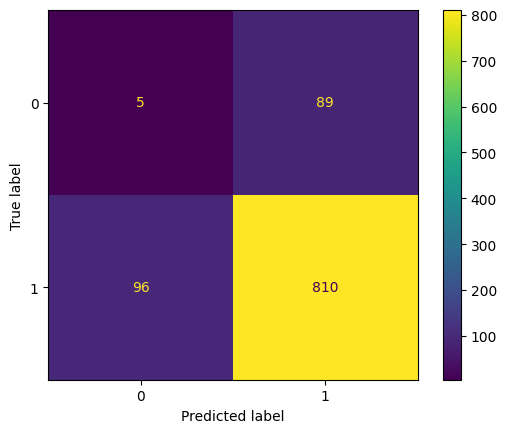

In [23]:
import matplotlib.pyplot as plt
import numpy
from sklearn import metrics

actual = numpy.random.binomial(1,.9,size = 1000)
predicted = numpy.random.binomial(1,.9,size = 1000)  #AP24110010563

confusion_matrix = metrics.confusion_matrix(actual, predicted)

cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [0, 1])

cm_display.plot()
plt.show()

The Confusion Matrix created above contains four different quadrants:

True Negative (Top-Left Quadrant)

False Positive (Top-Right Quadrant)

False Negative (Bottom-Left Quadrant)

True Positive (Bottom-Right Quadrant)

The term True means that the values were predicted correctly, while False indicates that an error or incorrect prediction occurred.

Now that we have created a Confusion Matrix, we can calculate different measures to determine the quality of the model. First, let's examine Accuracy.

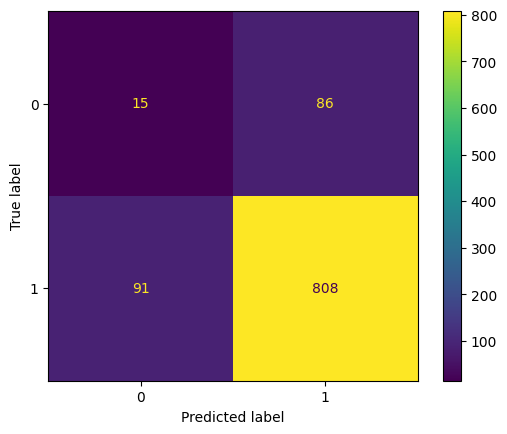

In [22]:
import matplotlib.pyplot as plt
import numpy
from sklearn import metrics

actual = numpy.random.binomial(1,.9,size = 1000)
predicted = numpy.random.binomial(1,.9,size = 1000) #AP24110010563

confusion_matrix = metrics.confusion_matrix(actual, predicted)

cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [0, 1])

cm_display.plot()
plt.show()

Decision trees are predictive models that are easy to understand while still being surprisingly expressive. A decision tree with a limited depth can serve as a useful starting point for classification tasks, and its complexity can be adjusted easily. For the final lesson, we will learn about random forests, which are an extension of decision trees and perform well across a wide range of classification tasks.